In [9]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplcursors
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit
from astropy.time import Time
from IPython.display import HTML
import os


#from scipy.signal import find_peaks
#import numpy.polynomial.polynomial as poly
#from numpy.polynomial import Polynomial
#import scipy.constants as const

In [2]:
#Datos de Betelguese, Antares y Ras Algethi 
ruta_datos_Smith = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos de fuentes externas\Análisis Smith\Smith.xlsx"

datos_betelgeuse = pd.read_excel(ruta_datos_Smith, usecols=[1, 2, 3], skiprows=2)

datos_antares = pd.read_excel(ruta_datos_Smith, usecols=[5, 6, 7], skiprows=2)

datos_antares = datos_antares.dropna()

datos_rasalgethi = pd.read_excel(ruta_datos_Smith, usecols=[9, 10, 11], skiprows=2)

datos_rasalgethi = datos_rasalgethi.dropna()

print("--- BETELGEUSE ---")
display(datos_betelgeuse.head())


print("--- ANTARES ---")
display(datos_antares.head())


print("--- RAS ALGETHI ---")
display(datos_rasalgethi.head())

--- BETELGEUSE ---


,Día Juliano,Líneas Metálicas,H_alpha
0,5982,22.81,-6.01
1,5992,25.37,-6.77
2,5993,26.07,-5.97
3,6018,25.49,-8.39
4,6025,25.16,-10.66


--- ANTARES ---


,Día Juliano.1,Líneas Metálicas.1,H_alpha.1
0,6072.0,-6.74,-11.60
1,6083.0,-6.38,-10.77
2,6106.0,-5.85,-11.98
3,6125.0,-5.96,-11.09
4,6159.0,-5.12,-11.18


--- RAS ALGETHI ---


,Día Juliano.2,Líneas Metálicas.2,H_alpha.2
0,6663.0,-32.12,-9.49
1,6670.0,-33.07,-6.48
2,6673.0,-33.12,-6.43
3,6675.0,-33.31,-5.73
4,6698.0,-35.08,-2.51


<h2 style="color: #e19edc;">Betelgeuse</h2>

<h3 style="color: #e19edc;"> Gráficas de las velocidades radiales de las líneas metálicas con las velocidades relativas de la línea H<sub>&alpha;</sub> de Betelgeuse</h3>

In [3]:
dias_julianos_betelgeuse = datos_betelgeuse['Día Juliano'].values
velocidad_metales_betelgeuse = datos_betelgeuse['Líneas Metálicas'].values
velocidad_hidrogeno_betelgeuse = datos_betelgeuse['H_alpha'].values

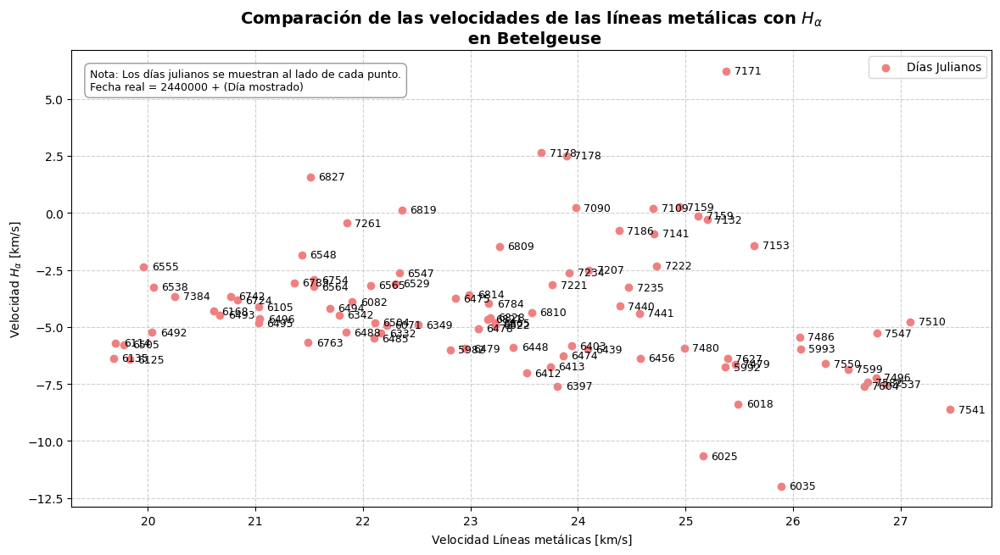

In [4]:
plt.close('all')
plt.figure(figsize=(14, 7))
plt.scatter(velocidad_metales_betelgeuse, velocidad_hidrogeno_betelgeuse, color = "lightcoral")

# Reconocer a que día hace referencia cada punto en el gráfico

for dia, v_metal, v_hidrogeno in zip(dias_julianos_betelgeuse, velocidad_metales_betelgeuse, velocidad_hidrogeno_betelgeuse):
    plt.text(
        v_metal + 0.075,     
        v_hidrogeno,       
        str(dia),          
        fontsize=9,        
        va='center'       
    )

plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
plt.ylabel(r"Velocidad $H_\alpha$ [$\mathrm{km/s}$]")
plt.title(f"Comparación de las velocidades de las líneas metálicas con $H_\\alpha$\n en Betelgeuse", fontsize=14, fontweight='bold')

ax = plt.gca()  #Mantiene el mismo eje de la gráfica

texto_nota = (
    "Nota: Los días julianos se muestran al lado de cada punto.\n"
    "Fecha real = 2440000 + (Día mostrado)"
)
ax.text(
    0.02, 0.96, texto_nota,  # 0.02 = casi al borde izquierdo, 0.96 = casi arriba
    transform=ax.transAxes,  # Coordenadas en fracción del eje
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
)
plt.legend(["Días Julianos"], loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

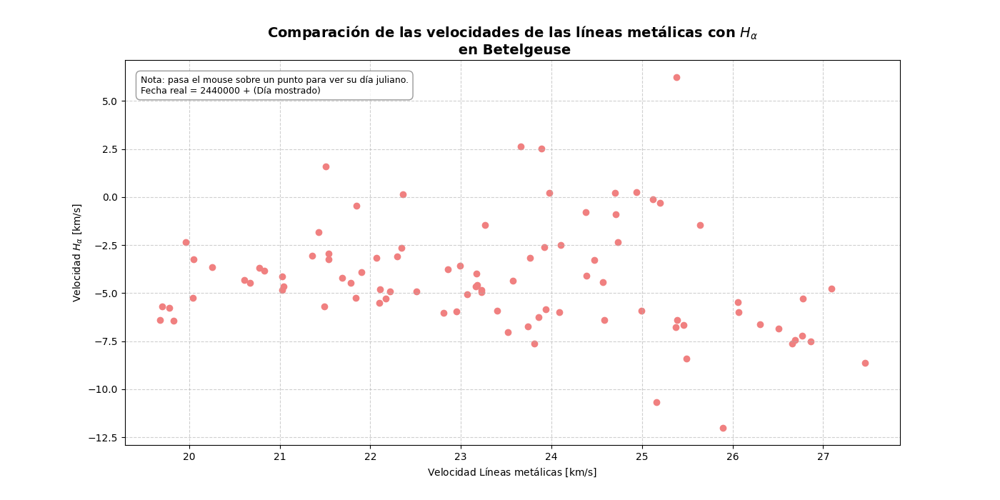

In [5]:
%matplotlib widget
#El widget se empleó para ver los datos de manera específica

plt.figure(figsize=(14, 7))
sc = plt.scatter(velocidad_metales_betelgeuse, velocidad_hidrogeno_betelgeuse, color="lightcoral")

plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
plt.ylabel(r"Velocidad $H_\alpha$ [$\mathrm{km/s}$]")
plt.title(f"Comparación de las velocidades de las líneas metálicas con $H_\\alpha$\n en Betelgeuse", fontsize=14, fontweight='bold')

ax = plt.gca()

texto_nota = (
    "Nota: pasa el mouse sobre un punto para ver su día juliano.\n"
    "Fecha real = 2440000 + (Día mostrado)"
)
ax.text(
    0.02, 0.96, texto_nota,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
)

plt.grid(True, linestyle='--', alpha=0.6)

# Cursor interactivo
cursor = mplcursors.cursor(sc, hover=True)

@cursor.connect("add")
def mostrar_dia(sel):
    i = sel.index  # índice del punto sobre el que está el mouse
    dia = dias_julianos_betelgeuse[i]
    sel.annotation.set_text(f"Día: {dia}\nFecha real: {2440000 + dia}")

plt.show()



<h4 style="color: #e19edc;"> Gráficas entre 1984 y 1989 de Betelgeuse</h4>

<h5 style="color: #e19edc;"> Gráficas Individuales</h5>

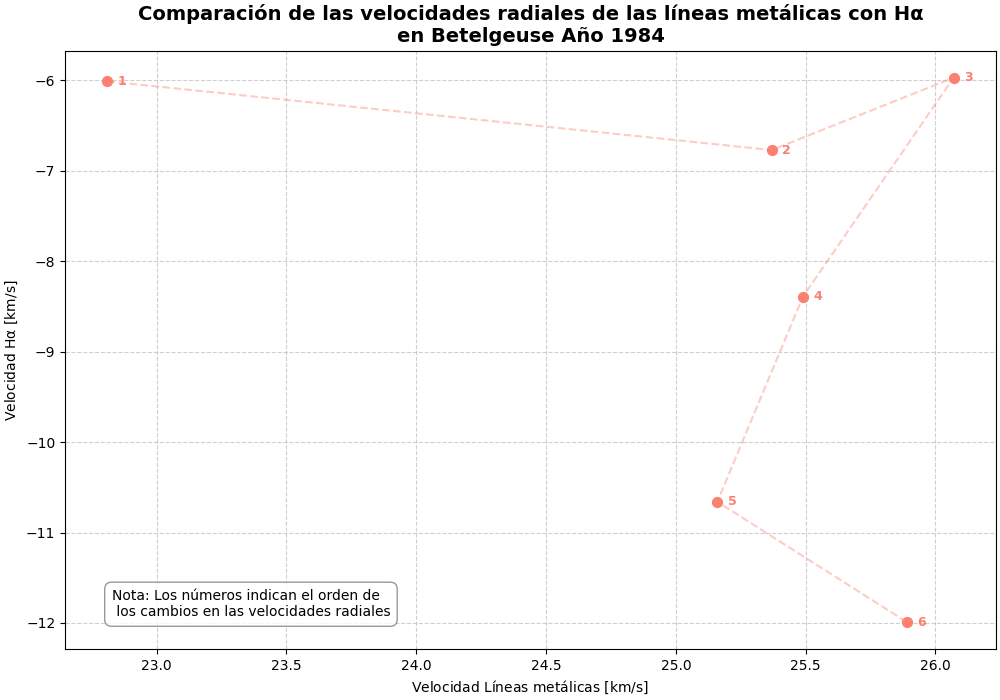

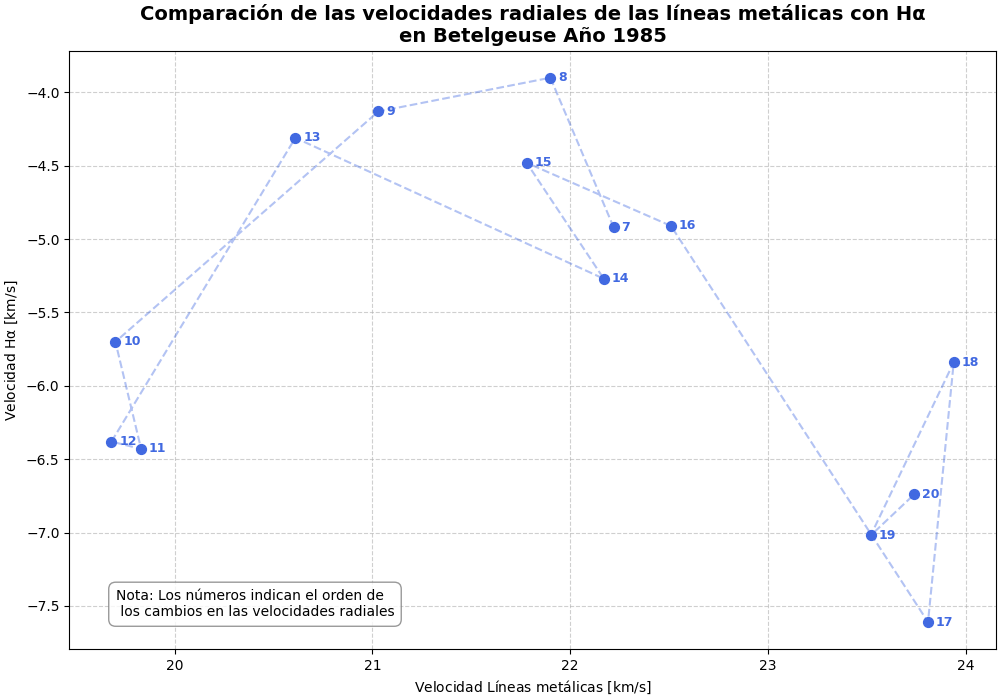

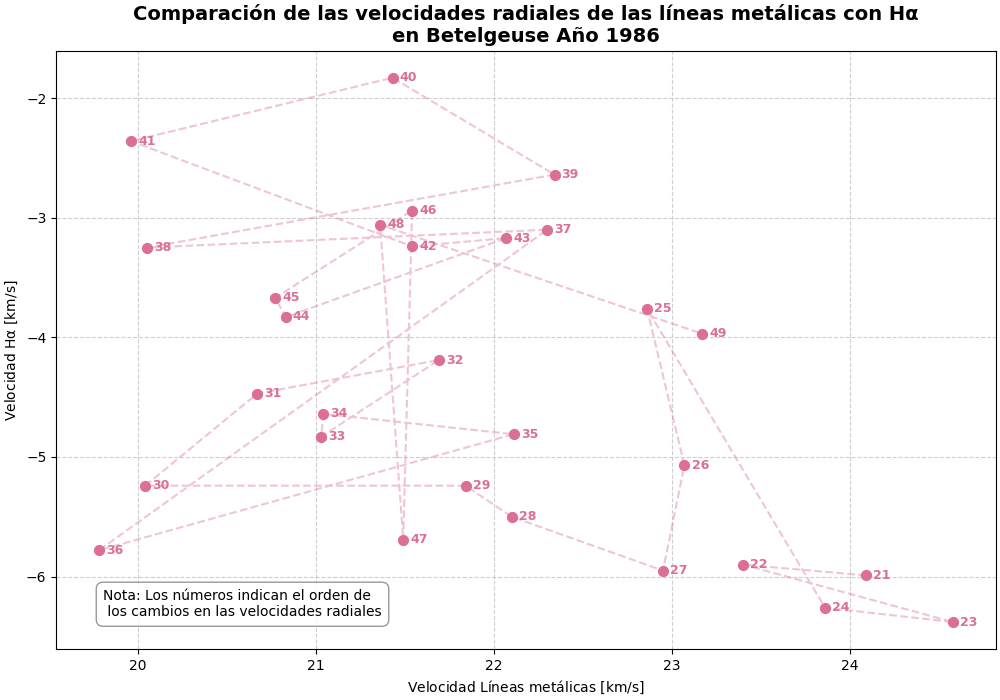

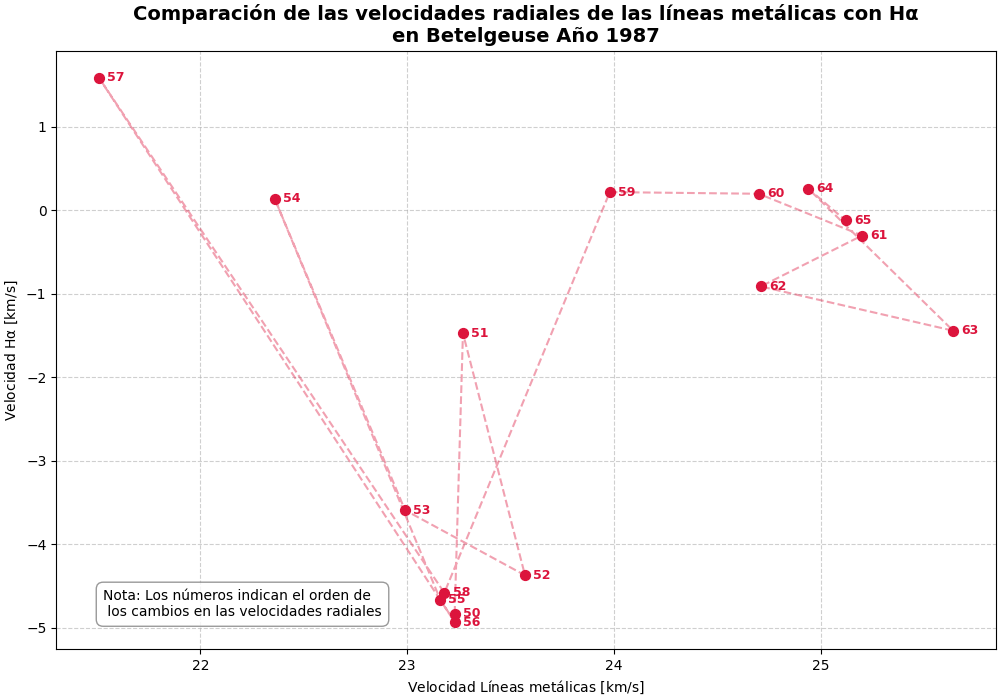

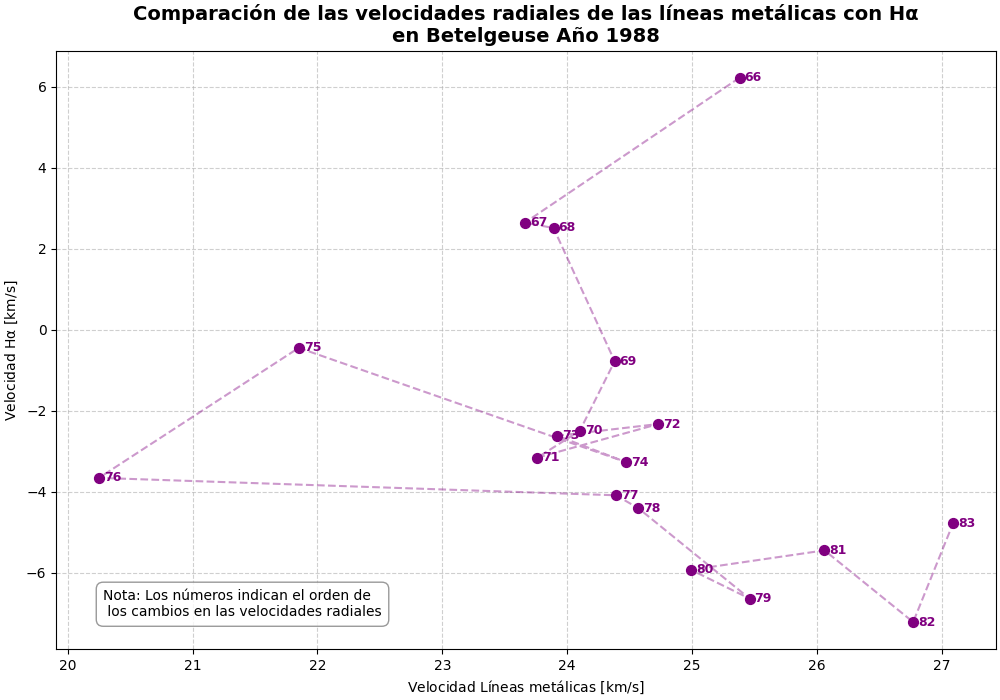

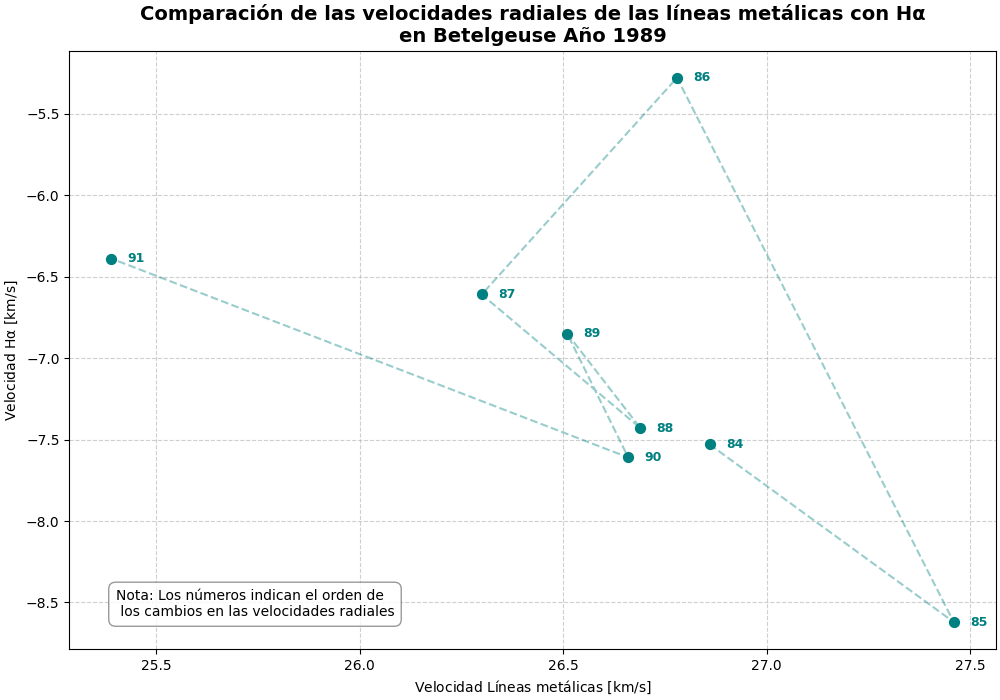

In [14]:
plt.close('all')

# Conversión de días julianos a años
dias_julianos_b_reales = 2440000 + dias_julianos_betelgeuse
observaciones_b = Time(dias_julianos_b_reales, format='jd')
anios_b = [t.year for t in observaciones_b.to_datetime()]

# DataFrame de Betelgeuse
df_betelgeuse = pd.DataFrame({
    'indice_original': range(1, len(dias_julianos_betelgeuse) + 1), 
    'dia_juliano_original': dias_julianos_betelgeuse,
    'v_metal': velocidad_metales_betelgeuse,
    'v_hidrogeno': velocidad_hidrogeno_betelgeuse,
    'anio': anios_b
})

colores_b = ['salmon', 'royalblue', 'palevioletred', 'crimson', 'purple', 'teal']
anios_unicos_b = sorted(df_betelgeuse['anio'].unique())

# Creación de gráficas por año
for i, anio_actual in enumerate(anios_unicos_b):
    df_anio = df_betelgeuse[df_betelgeuse['anio'] == anio_actual]
    
    plt.figure(figsize=(10, 7), constrained_layout=True)
    
  
    color_actual = colores_b[i % len(colores_b)]
    
    
    plt.scatter(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, s=50, zorder=3)

    plt.plot(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, linestyle='--', alpha=0.4, zorder=2)

    
    for _, row in df_anio.iterrows():
        plt.text(
            row['v_metal'] + 0.04,  
            row['v_hidrogeno'],     
            str(int(row['indice_original'])),  
            fontsize=9,
            fontweight='bold',
            va='center',
            color=color_actual
        )

    plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    plt.title(r"Comparación de las velocidades radiales de las líneas metálicas con Hα" + "\n"+ "en Betelgeuse Año %d" % anio_actual, fontsize=14, fontweight='bold')

    ax = plt.gca()

    texto_nota = ("Nota: Los números indican el orden de \n los cambios en las velocidades radiales")
    ax.text(
        0.05, 0.05, texto_nota,
        transform=ax.transAxes,
        fontsize=10,
        horizontalalignment='left',
        verticalalignment='bottom',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
    )

    plt.savefig(f"Gráficas estrellas Smith/Betelgeuse/Betelgeuse_Año_{anio_actual}.png", dpi=300)
    
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()
    

<h5 style="color: #e19edc;"> Gráfica Conjunta</h5>

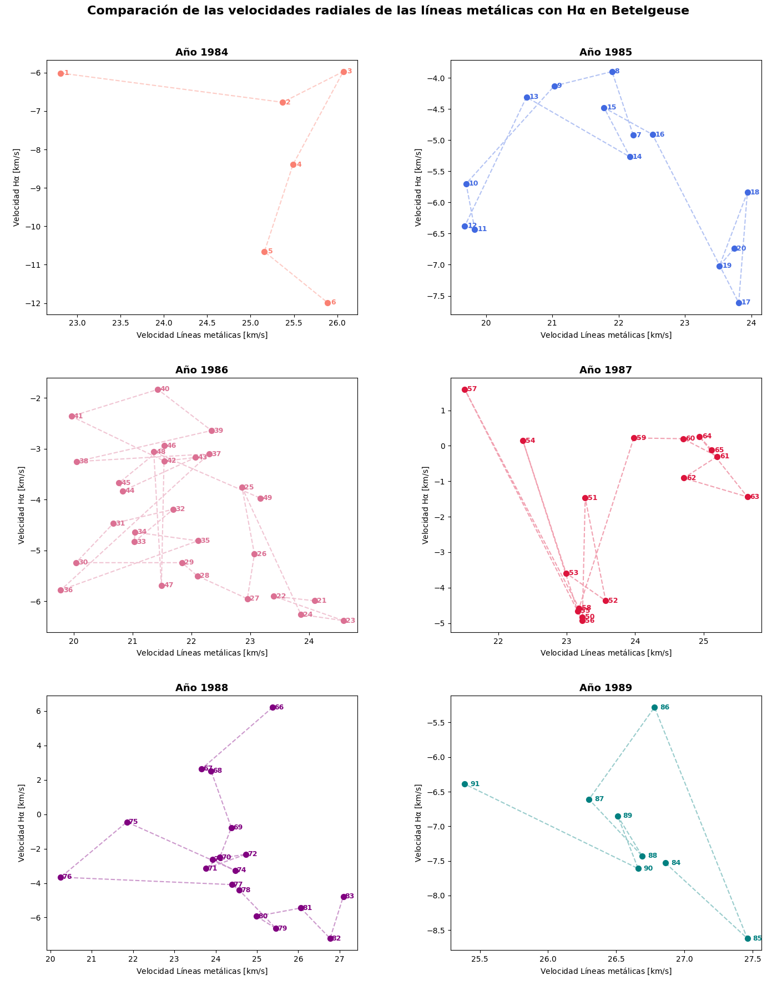

In [50]:
plt.close('all')

carpeta_salida_b = "Gráficas estrellas Smith/Betelgeuse"
os.makedirs(carpeta_salida_b, exist_ok=True)

def dibujar_anio_en_ax(ax, df_anio, anio_actual, color_actual):

    ax.scatter(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, s=50, zorder=3)
    ax.plot(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, linestyle='--', alpha=0.4, zorder=2)

    for _, row in df_anio.iterrows():
        ax.text(
            row['v_metal'] + 0.04,
            row['v_hidrogeno'],
            str(int(row['indice_original'])),
            fontsize=9,
            fontweight='bold',
            va='center',
            color=color_actual
        )

    ax.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    ax.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    ax.set_title(f"Año {anio_actual}", fontsize=13, fontweight='bold')

# Figuras a doble columna

n_anios = len(anios_unicos_b)
n_columnas = 2
n_filas = int(np.ceil(n_anios / n_columnas))

fig = plt.figure(figsize=(14, 6 * n_filas))
gs = GridSpec(n_filas, n_columnas, figure=fig, hspace=0.25, wspace=0.3)

for i, anio_actual in enumerate(anios_unicos_b):

    df_anio = df_betelgeuse[df_betelgeuse['anio'] == anio_actual]
    color_actual = colores_b[i % len(colores_b)]

    fila = i // n_columnas
    columna = i % n_columnas

    es_ultima = (i == n_anios - 1)
    es_impar = (n_anios % 2 == 1)

    if es_ultima and es_impar:

        gs_centro = gs[fila, :].subgridspec(1, 4, wspace=0.15)
        ax = fig.add_subplot(gs_centro[0, 1:3])
    else:
        ax = fig.add_subplot(gs[fila, columna])

    dibujar_anio_en_ax(ax, df_anio, anio_actual, color_actual)

fig.suptitle(r"Comparación de las velocidades radiales de las líneas metálicas con Hα en Betelgeuse",
             fontsize=16, fontweight='bold', y=0.995)
 
fig.subplots_adjust(top=0.94, bottom=0.05, left=0.06, right=0.98)

fig.savefig(f"{carpeta_salida_b}/Betelgeuse_todos_los_años.png", dpi=300, bbox_inches="tight")

plt.show()

<h3 style="color: #e19edc;"> Animaciones de las comparaciones de las velocidades radiales de Betelgeuse</h3>

<h4 style="color: #e19edc;"> Animaciones por año</h4>

In [26]:
for i, anio_actual in enumerate(anios_unicos_b):
    df_anio = df_betelgeuse[df_betelgeuse['anio'] == anio_actual].reset_index(drop=True)
    color_actual = colores_b[i % len(colores_b)]

    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Límites de las imágenes de acuerdo con los datos por cada año (Margen del 20%)
    margen_x = (df_anio['v_metal'].max() - df_anio['v_metal'].min()) * 0.2 + 0.1
    margen_y = (df_anio['v_hidrogeno'].max() - df_anio['v_hidrogeno'].min()) * 0.2 + 0.1
    ax.set_xlim(df_anio['v_metal'].min() - margen_x, df_anio['v_metal'].max() + margen_x)
    ax.set_ylim(df_anio['v_hidrogeno'].min() - margen_y, df_anio['v_hidrogeno'].max() + margen_y)
    
    ax.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    ax.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    ax.set_title(r"Evolución temporal de Betelgeuse - Año %d" % anio_actual, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Elementos de la animación: punto y trayectoria
    linea_trayectoria, = ax.plot([], [], color=color_actual, linestyle='--', alpha=0.5, zorder=2)
    punto_actual, = ax.plot([], [], marker='o', color=color_actual, markersize=8, zorder=3)
    
    def actualizar_anio(frame):
        x_datos = df_anio['v_metal'].iloc[:frame+1]
        y_datos = df_anio['v_hidrogeno'].iloc[:frame+1]
        
        linea_trayectoria.set_data(x_datos, y_datos)
        if len(x_datos) > 0:
            punto_actual.set_data([x_datos.iloc[-1]], [y_datos.iloc[-1]])
            
        return linea_trayectoria, punto_actual

    # Creamos la animación 
    anim = FuncAnimation(fig, actualizar_anio, frames=len(df_anio), interval=300, blit=True)

    anim.save(f"Animaciones estrellas Smith/Betelgeuse/betelgeuse_en_{anio_actual}.mp4", writer="ffmpeg", fps=2,  dpi=150)

    plt.close(fig) 
    
    # Animación en Jupyter
    display(HTML(anim.to_jshtml()))

<h4 style="color: #e19edc;"> Animación conjunta de Betelgeuse en el periodo de 1984 a 1989</h4>

In [27]:
fig_conjunta, ax_c = plt.subplots(figsize=(9, 7))

ax_c.set_xlim(df_betelgeuse['v_metal'].min() - 1, df_betelgeuse['v_metal'].max() + 1)
ax_c.set_ylim(df_betelgeuse['v_hidrogeno'].min() - 1, df_betelgeuse['v_hidrogeno'].max() + 1)
ax_c.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
ax_c.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
ax_c.set_title(r"Trayectorias conjuntas de Betelgeuse por Año", fontsize=13, fontweight='bold')
ax_c.grid(True, linestyle='--', alpha=0.6)

lineas_conjuntas = []
for i, anio_actual in enumerate(anios_unicos_b):
    color_actual = colores_b[i % len(colores_b)]
    l, = ax_c.plot([], [], color=color_actual, linestyle='--', alpha=0.6, label=f"Año {anio_actual}", zorder=2)
    lineas_conjuntas.append(l)

punto_unico, = ax_c.plot([], [], marker='o', color='black', markeredgecolor='white', markersize=9, zorder=4, label="Posición actual")

ax_c.legend(loc='upper right', framealpha=0.9)

# Se almacenan los datos por año
datos_por_anio = []
for anio_actual in anios_unicos_b:
    df_anio = df_betelgeuse[df_betelgeuse['anio'] == anio_actual].reset_index(drop=True)
    datos_por_anio.append(df_anio)

secuencia_frames = []
for i, df_anio in enumerate(datos_por_anio):
    for punto_idx in range(len(df_anio)):
        secuencia_frames.append((i, punto_idx))

def actualizar_conjunto(frame):
    anio_idx_actual, punto_idx_actual = secuencia_frames[frame]

    # Años pasados (Se grafican las trayectorias completas de los años anteriores)
    for i in range(anio_idx_actual):
        df_anio = datos_por_anio[i]
        x_vals = list(df_anio['v_metal'])
        y_vals = list(df_anio['v_hidrogeno'])

        # Unión entre años distintos
        if i > 0 and len(datos_por_anio[i - 1]) > 0:
            x_vals = [datos_por_anio[i - 1]['v_metal'].iloc[-1]] + x_vals
            y_vals = [datos_por_anio[i - 1]['v_hidrogeno'].iloc[-1]] + y_vals
        lineas_conjuntas[i].set_data(x_vals, y_vals)

    # Años futuros
    for i in range(anio_idx_actual + 1, len(datos_por_anio)):
        lineas_conjuntas[i].set_data([], [])

    # Año actual
    df_actual = datos_por_anio[anio_idx_actual]
    x_datos = list(df_actual['v_metal'].iloc[:punto_idx_actual + 1])
    y_datos = list(df_actual['v_hidrogeno'].iloc[:punto_idx_actual + 1])

    # Unión entre años distintos
    if anio_idx_actual > 0 and len(datos_por_anio[anio_idx_actual - 1]) > 0:
        x_datos = [datos_por_anio[anio_idx_actual - 1]['v_metal'].iloc[-1]] + x_datos
        y_datos = [datos_por_anio[anio_idx_actual - 1]['v_hidrogeno'].iloc[-1]] + y_datos

    lineas_conjuntas[anio_idx_actual].set_data(x_datos, y_datos)

    # Punto estudio
    punto_unico.set_data([x_datos[-1]], [y_datos[-1]])

    return lineas_conjuntas + [punto_unico]

anim_conjunta = FuncAnimation(
    fig_conjunta, actualizar_conjunto,
    frames=len(secuencia_frames), interval=250, blit=True
)

anim_conjunta.save( "Animaciones estrellas Smith/Betelgeuse/betelgeuse_trayectorias.mp4", writer="ffmpeg", fps=2,  dpi=150)

plt.close(fig_conjunta)

display(HTML(anim_conjunta.to_jshtml()))

<h2 style="color: #e19edc;">Antares</h2>

<h3 style="color: #e19edc;"> Gráficas de las velocidades radiales de las líneas metálicas con las velocidades relativas de la línea H<sub>&alpha;</sub> de Antares</h3>

In [11]:
dias_julianos_antares = datos_antares['Día Juliano.1'].values
velocidad_metales_antares = datos_antares['Líneas Metálicas.1'].values
velocidad_hidrogeno_antares = datos_antares['H_alpha.1'].values

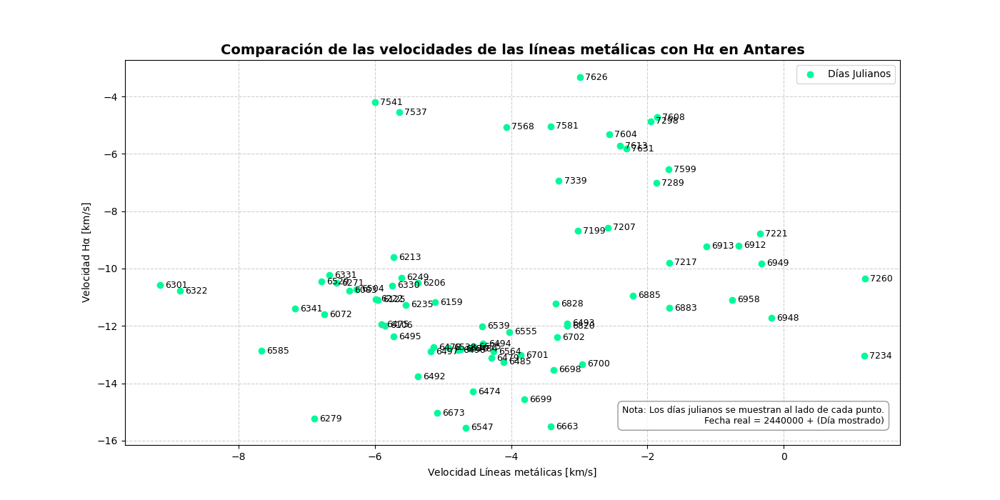

In [30]:
plt.figure(figsize=(14, 7))
plt.scatter(velocidad_metales_antares, velocidad_hidrogeno_antares, color = "mediumspringgreen")

for dia_1, v_metal_1, v_hidrogeno_1 in zip(dias_julianos_antares, velocidad_metales_antares, velocidad_hidrogeno_antares):
    plt.text(
        v_metal_1 + 0.075,     
        v_hidrogeno_1,       
        str(int(dia_1)),          
        fontsize=9,        
        va='center'       
    )

plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
plt.title(r"Comparación de las velocidades de las líneas metálicas con Hα en Antares", fontsize=14, fontweight='bold')

ax = plt.gca()

texto_nota = (
    "Nota: Los días julianos se muestran al lado de cada punto.\n"
    "Fecha real = 2440000 + (Día mostrado)"
)
ax.text(
    0.98, 0.05, texto_nota,  # 0.98 = casi al borde derecho, 0.05 = casi abajo
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='bottom',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
)
plt.legend(["Días Julianos"], loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

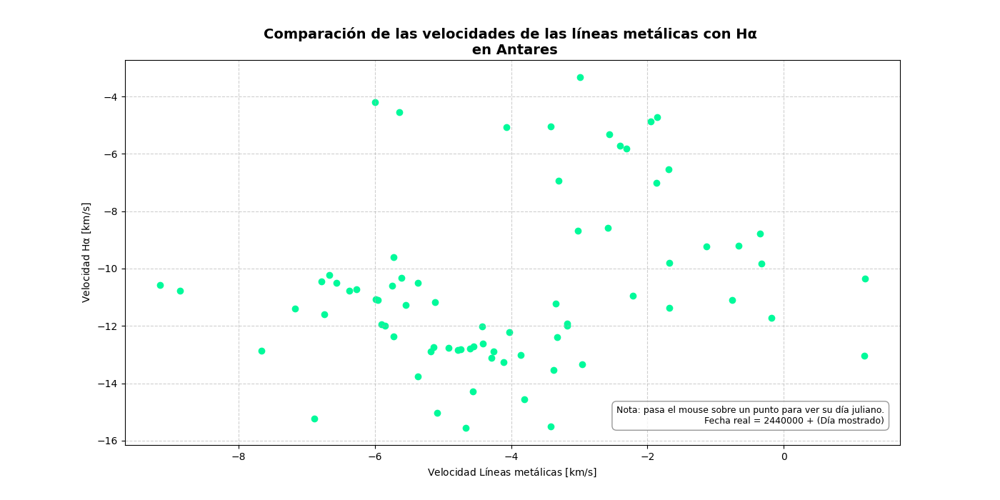

In [31]:
plt.figure(figsize=(14, 7))
sc = plt.scatter(velocidad_metales_antares, velocidad_hidrogeno_antares, color="mediumspringgreen")

plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
plt.title(f"Comparación de las velocidades de las líneas metálicas con Hα \n en Antares", fontsize=14, fontweight='bold')

ax = plt.gca()

texto_nota = (
    "Nota: pasa el mouse sobre un punto para ver su día juliano.\n"
    "Fecha real = 2440000 + (Día mostrado)"
)
ax.text(
    0.98, 0.05, texto_nota,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='bottom',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
)

plt.grid(True, linestyle='--', alpha=0.6)

# Cursor interactivo
cursor = mplcursors.cursor(sc, hover=True)

@cursor.connect("add")
def mostrar_dia(sel):
    i = sel.index  # índice del punto sobre el que está el mouse
    dia = dias_julianos_antares[i]
    sel.annotation.set_text(f"Día: {dia}\nFecha real: {2440000 + dia}")

plt.show()

<h4 style="color: #e19edc;"> Gráficas entre 1985 y 1989 de Antares</h4>

<h5 style="color: #e19edc;"> Gráficas Individuales</h5>

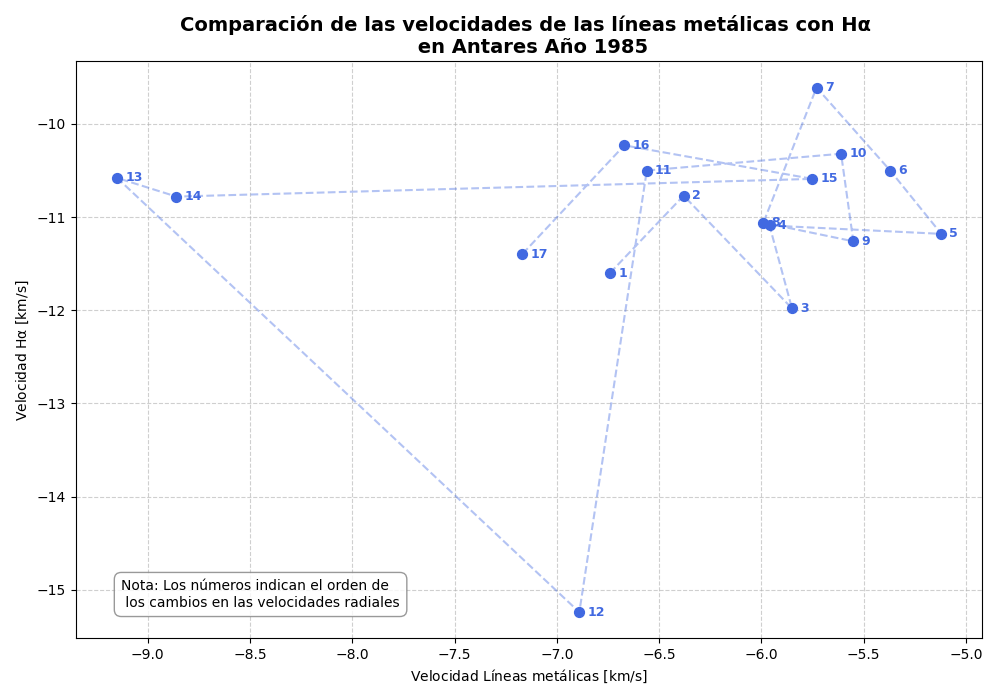

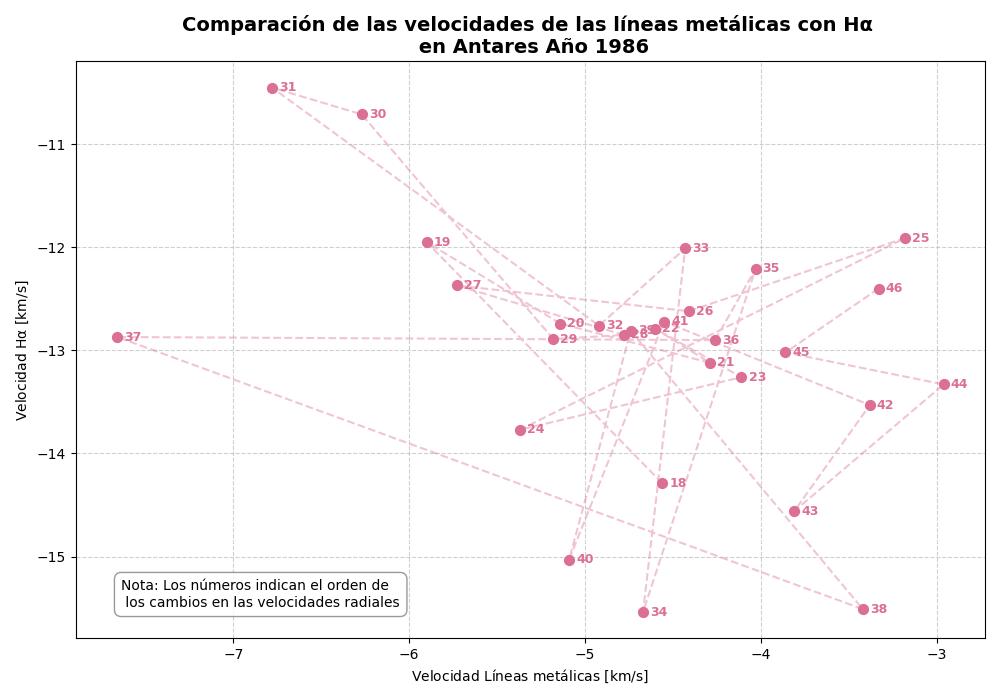

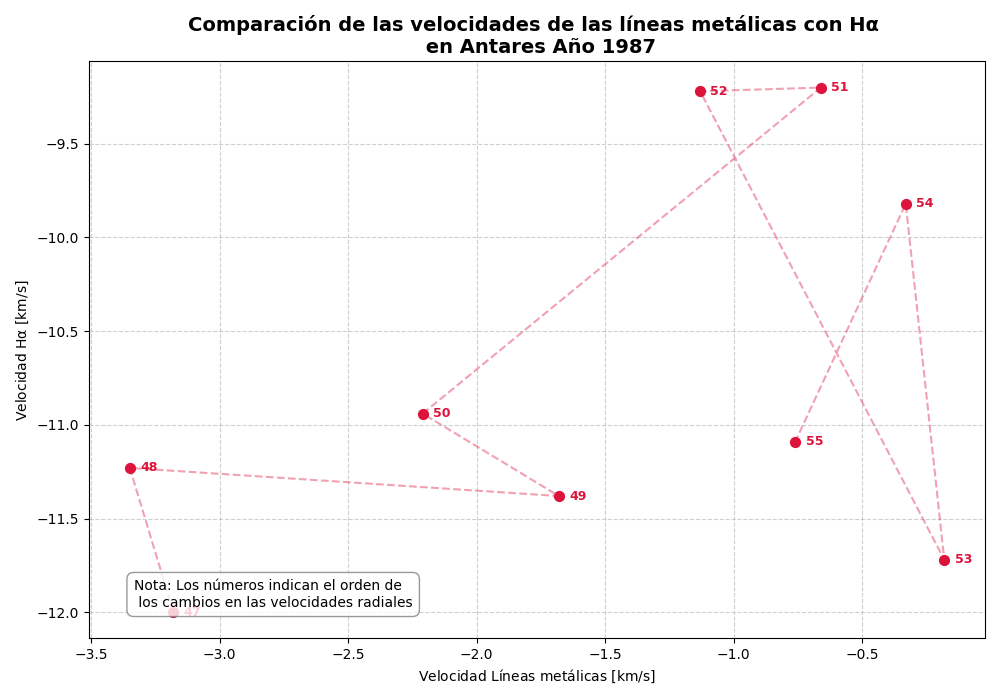

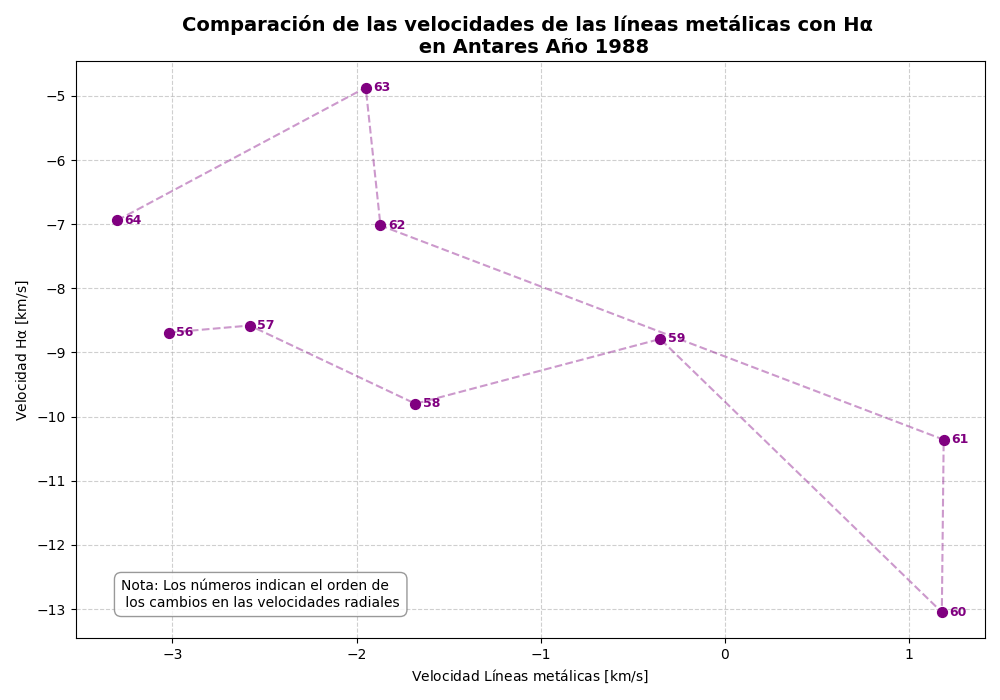

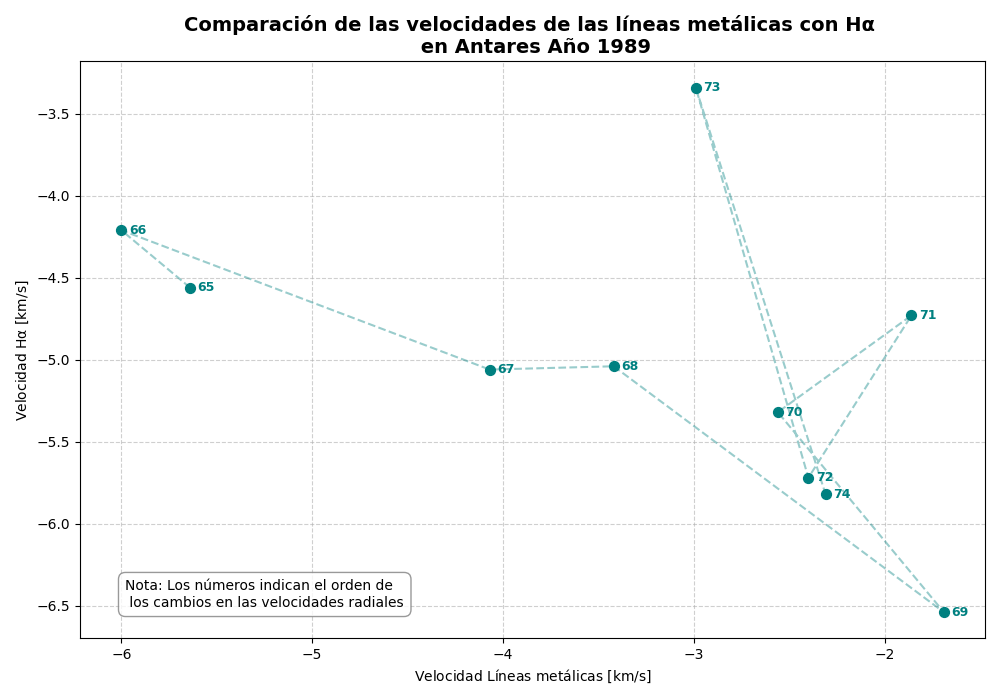

In [32]:
# Conversión de días julianos a años
dias_julianos_a_reales = 2440000 + dias_julianos_antares
observaciones_a = Time(dias_julianos_a_reales, format='jd')
anios_a = [t.year for t in observaciones_a.to_datetime()]

# DataFrame de Antares
df_antares = pd.DataFrame({
    'indice_original': range(1, len(dias_julianos_antares) + 1), 
    'dia_juliano_original': dias_julianos_antares,
    'v_metal': velocidad_metales_antares,
    'v_hidrogeno': velocidad_hidrogeno_antares,
    'anio': anios_a
})

# Colores para cada año
colores_a = ['royalblue', 'palevioletred', 'crimson', 'purple', 'teal']
anios_unicos_a = sorted(df_antares['anio'].unique())

# Creación de gráficas por año
for i, anio_actual in enumerate(anios_unicos_a):
    df_anio = df_antares[df_antares['anio'] == anio_actual]
    
    plt.figure(figsize=(10, 7))
    
  
    color_actual = colores_a[i % len(colores_a)]
    
    
    plt.scatter(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, s=50, zorder=3)

    plt.plot(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, linestyle='--', alpha=0.4, zorder=2)

    
    for _, row in df_anio.iterrows():
        plt.text(
            row['v_metal'] + 0.04,  
            row['v_hidrogeno'],     
            str(int(row['indice_original'])),  
            fontsize=9,
            fontweight='bold',
            va='center',
            color=color_actual
        )

    plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    plt.title(f"Comparación de las velocidades de las líneas metálicas con Hα \n en Antares Año {anio_actual}", fontsize=14, fontweight='bold')

    ax = plt.gca()

    texto_nota = (
        "Nota: Los números indican el orden de \n los cambios en las velocidades radiales"
    )
    ax.text(
        0.05, 0.05, texto_nota,
        transform=ax.transAxes,
        fontsize=10,
        horizontalalignment='left',
        verticalalignment='bottom',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
    )
    
    plt.savefig(f"Gráficas estrellas Smith/Antares/Antares_Año_{anio_actual}.png", dpi=300)

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

<h5 style="color: #e19edc;"> Gráfica Conjunta</h5>

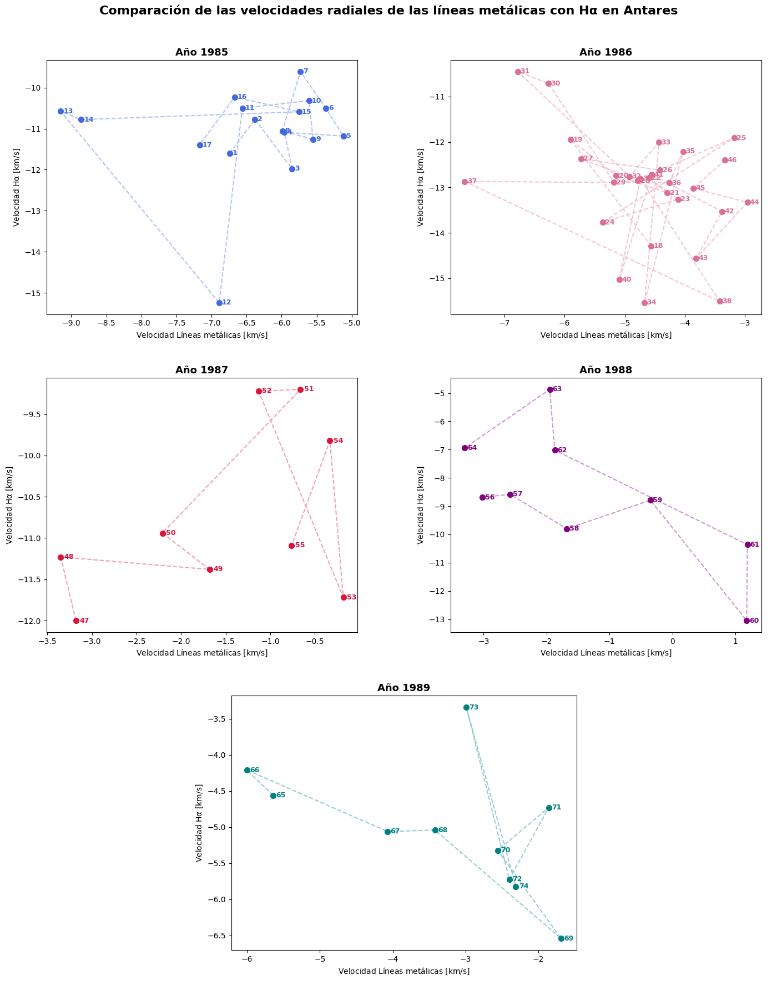

In [49]:
plt.close('all')

carpeta_salida_a = "Gráficas estrellas Smith/Antares"
os.makedirs(carpeta_salida_a, exist_ok=True)

def dibujar_anio_en_ax(ax, df_anio, anio_actual, color_actual):

    ax.scatter(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, s=50, zorder=3)
    ax.plot(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, linestyle='--', alpha=0.4, zorder=2)

    for _, row in df_anio.iterrows():
        ax.text(
            row['v_metal'] + 0.04,
            row['v_hidrogeno'],
            str(int(row['indice_original'])),
            fontsize=9,
            fontweight='bold',
            va='center',
            color=color_actual
        )

    ax.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    ax.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    ax.set_title(f"Año {anio_actual}", fontsize=13, fontweight='bold')

# Figuras a doble columna

n_anios = len(anios_unicos_a)
n_columnas = 2
n_filas = int(np.ceil(n_anios / n_columnas))

fig = plt.figure(figsize=(14, 6 * n_filas))
gs = GridSpec(n_filas, n_columnas, figure=fig, hspace=0.25, wspace=0.3)

for i, anio_actual in enumerate(anios_unicos_a):

    df_anio = df_antares[df_antares['anio'] == anio_actual]
    color_actual = colores_a[i % len(colores_a)]

    fila = i // n_columnas
    columna = i % n_columnas

    es_ultima = (i == n_anios - 1)
    es_impar = (n_anios % 2 == 1)

    if es_ultima and es_impar:

        gs_centro = gs[fila, :].subgridspec(1, 4, wspace=0.15)
        ax = fig.add_subplot(gs_centro[0, 1:3])
    else:
        ax = fig.add_subplot(gs[fila, columna])

    dibujar_anio_en_ax(ax, df_anio, anio_actual, color_actual)

fig.suptitle(r"Comparación de las velocidades radiales de las líneas metálicas con Hα en Antares",
             fontsize=16, fontweight='bold', y=0.995)
 
fig.subplots_adjust(top=0.94, bottom=0.05, left=0.06, right=0.98)

fig.savefig(f"{carpeta_salida_a}/Antares_todos_los_años.png", dpi=300, bbox_inches="tight")

plt.show()

<h3 style="color: #e19edc;"> Animaciones de las comparaciones de las velocidades radiales de Antares</h3>

<h4 style="color: #e19edc;"> Animaciones por año</h4>

In [36]:
for i, anio_actual in enumerate(anios_unicos_a):
    df_anio = df_antares[df_antares['anio'] == anio_actual].reset_index(drop=True)
    color_actual = colores_a[i % len(colores_a)]

    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Límites de las imágenes de acuerdo con los datos por cada año (Margen del 20%)
    margen_x = (df_anio['v_metal'].max() - df_anio['v_metal'].min()) * 0.2 + 0.1
    margen_y = (df_anio['v_hidrogeno'].max() - df_anio['v_hidrogeno'].min()) * 0.2 + 0.1
    ax.set_xlim(df_anio['v_metal'].min() - margen_x, df_anio['v_metal'].max() + margen_x)
    ax.set_ylim(df_anio['v_hidrogeno'].min() - margen_y, df_anio['v_hidrogeno'].max() + margen_y)
    
    ax.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    ax.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    ax.set_title(r"Evolución temporal de Antares - Año %d" % anio_actual, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Elementos de la animación: punto y trayectoria
    linea_trayectoria, = ax.plot([], [], color=color_actual, linestyle='--', alpha=0.5, zorder=2)
    punto_actual, = ax.plot([], [], marker='o', color=color_actual, markersize=8, zorder=3)
    
    def actualizar_anio(frame):
        x_datos = df_anio['v_metal'].iloc[:frame+1]
        y_datos = df_anio['v_hidrogeno'].iloc[:frame+1]
        
        linea_trayectoria.set_data(x_datos, y_datos)
        if len(x_datos) > 0:
            punto_actual.set_data([x_datos.iloc[-1]], [y_datos.iloc[-1]])
            
        return linea_trayectoria, punto_actual

    # Creamos la animación 
    anim = FuncAnimation(fig, actualizar_anio, frames=len(df_anio), interval=300, blit=True)

    anim.save(f"Animaciones estrellas Smith/Antares/antares_en_{anio_actual}.mp4", writer="ffmpeg", fps=2,  dpi=150)

    plt.close(fig) 
    
    # Animación en Jupyter
    display(HTML(anim.to_jshtml()))

<h4 style="color: #e19edc;"> Animación conjunta de Antares en el periodo de 1985 a 1989</h4>

In [37]:
fig_conjunta_a, ax_c = plt.subplots(figsize=(9, 7))

ax_c.set_xlim(df_antares['v_metal'].min() - 1, df_antares['v_metal'].max() + 1)
ax_c.set_ylim(df_antares['v_hidrogeno'].min() - 1, df_antares['v_hidrogeno'].max() + 1)
ax_c.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
ax_c.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
ax_c.set_title(r"Trayectorias conjuntas de Antares por Año", fontsize=13, fontweight='bold')
ax_c.grid(True, linestyle='--', alpha=0.6)

lineas_conjuntas_a = []
for i, anio_actual in enumerate(anios_unicos_a):
    color_actual = colores_a[i % len(colores_a)]
    l, = ax_c.plot([], [], color=color_actual, linestyle='--', alpha=0.6, label=f"Año {anio_actual}", zorder=2)
    lineas_conjuntas_a.append(l)

punto_unico, = ax_c.plot([], [], marker='o', color='black', markeredgecolor='white', markersize=9, zorder=4, label="Posición actual")

ax_c.legend(loc='upper right', framealpha=0.9)

# Se almacenan los datos por año
datos_por_anio_a = []
for anio_actual in anios_unicos_a:
    df_anio = df_antares[df_antares['anio'] == anio_actual].reset_index(drop=True)
    datos_por_anio_a.append(df_anio)

secuencia_frames_a = []
for i, df_anio in enumerate(datos_por_anio_a):
    for punto_idx in range(len(df_anio)):
        secuencia_frames_a.append((i, punto_idx))

def actualizar_conjunto(frame):
    anio_idx_actual, punto_idx_actual = secuencia_frames_a[frame]

    # Años pasados (Se grafican las trayectorias completas de los años anteriores)
    for i in range(anio_idx_actual):
        df_anio = datos_por_anio_a[i]
        x_vals = list(df_anio['v_metal'])
        y_vals = list(df_anio['v_hidrogeno'])

        # Unión entre años distintos
        if i > 0 and len(datos_por_anio_a[i - 1]) > 0:
            x_vals = [datos_por_anio_a[i - 1]['v_metal'].iloc[-1]] + x_vals
            y_vals = [datos_por_anio_a[i - 1]['v_hidrogeno'].iloc[-1]] + y_vals
        lineas_conjuntas_a[i].set_data(x_vals, y_vals)

    # Años futuros
    for i in range(anio_idx_actual + 1, len(datos_por_anio_a)):
        lineas_conjuntas_a[i].set_data([], [])

    # Año actual
    df_actual = datos_por_anio_a[anio_idx_actual]
    x_datos = list(df_actual['v_metal'].iloc[:punto_idx_actual + 1])
    y_datos = list(df_actual['v_hidrogeno'].iloc[:punto_idx_actual + 1])

    # Unión entre años distintos
    if anio_idx_actual > 0 and len(datos_por_anio_a[anio_idx_actual - 1]) > 0:
        x_datos = [datos_por_anio_a[anio_idx_actual - 1]['v_metal'].iloc[-1]] + x_datos
        y_datos = [datos_por_anio_a[anio_idx_actual - 1]['v_hidrogeno'].iloc[-1]] + y_datos

    lineas_conjuntas_a[anio_idx_actual].set_data(x_datos, y_datos)

    # Punto estudio
    punto_unico.set_data([x_datos[-1]], [y_datos[-1]])

    return lineas_conjuntas_a + [punto_unico]

anim_conjunta_a = FuncAnimation(
    fig_conjunta_a, actualizar_conjunto,
    frames=len(secuencia_frames_a), interval=250, blit=True
)

anim_conjunta_a.save( "Animaciones estrellas Smith/Antares/antares_trayectorias.mp4", writer="ffmpeg", fps=2,  dpi=150)

plt.close(fig_conjunta_a)

display(HTML(anim_conjunta_a.to_jshtml()))

<h2 style="color: #e19edc;">Ras Algethi</h2>

<h3 style="color: #e19edc;"> Gráficas de las velocidades radiales de las líneas metálicas con las velocidades relativas de la línea H<sub>&alpha;</sub> de Ras Algethi</h3>

In [12]:
dias_julianos_rasalgethi = datos_rasalgethi['Día Juliano.2'].values
velocidad_metales_rasalgethi = datos_rasalgethi['Líneas Metálicas.2'].values
velocidad_hidrogeno_rasalgethi = datos_rasalgethi['H_alpha.2'].values

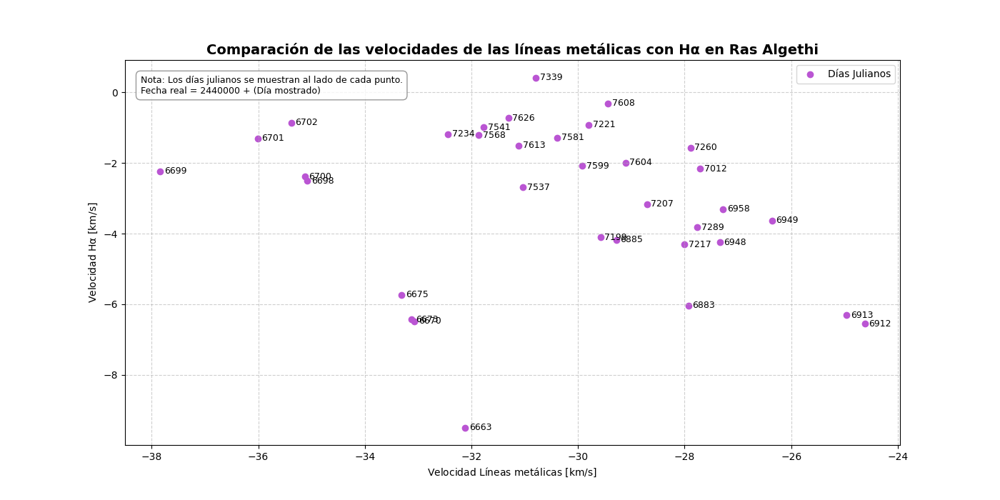

In [40]:
plt.close("all")
plt.figure(figsize=(14, 7))
plt.scatter(velocidad_metales_rasalgethi, velocidad_hidrogeno_rasalgethi, color = "mediumorchid")


for dia_2, v_metal_2, v_hidrogeno_2 in zip(dias_julianos_rasalgethi, velocidad_metales_rasalgethi, velocidad_hidrogeno_rasalgethi):
    plt.text(
        v_metal_2 + 0.075,     
        v_hidrogeno_2,       
        str(int(dia_2)),          
        fontsize=9,        
        va='center'       
    )

plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
plt.title(r"Comparación de las velocidades de las líneas metálicas con Hα en Ras Algethi", fontsize=14, fontweight='bold')

ax = plt.gca()  #Mantiene el mismo eje de la gráfica

texto_nota = (
    "Nota: Los días julianos se muestran al lado de cada punto.\n"
    "Fecha real = 2440000 + (Día mostrado)"
)
ax.text(
    0.02, 0.96, texto_nota,  # 0.02 = casi al borde izquierdo, 0.96 = casi arriba
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
)
plt.legend(["Días Julianos"], loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

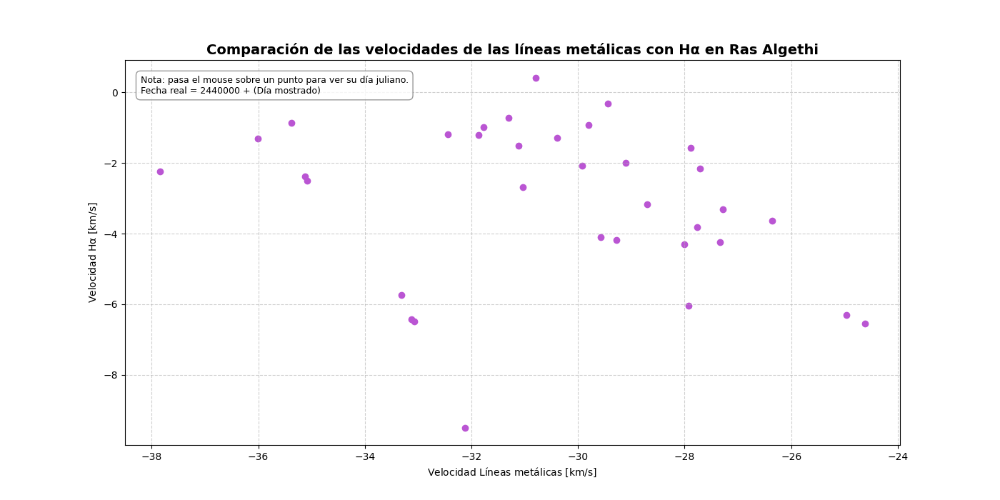

In [41]:
plt.figure(figsize=(14, 7))
sc = plt.scatter(velocidad_metales_rasalgethi, velocidad_hidrogeno_rasalgethi, color="mediumorchid")

plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
plt.title(r"Comparación de las velocidades de las líneas metálicas con Hα en Ras Algethi",fontsize=14, fontweight='bold')

ax = plt.gca()

texto_nota = (
    "Nota: pasa el mouse sobre un punto para ver su día juliano.\n"
    "Fecha real = 2440000 + (Día mostrado)"
)
ax.text(
    0.02, 0.96, texto_nota,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
)

plt.grid(True, linestyle='--', alpha=0.6)

# Aquí está la magia: conecta el cursor interactivo al scatter
cursor = mplcursors.cursor(sc, hover=True)

@cursor.connect("add")
def mostrar_dia(sel):
    i = sel.index  # índice del punto sobre el que está el mouse
    dia = dias_julianos_rasalgethi[i]
    dia = int(dia)
    sel.annotation.set_text(f"Día: {dia}\nFecha real: {2440000 + dia}")

plt.show()

<h4 style="color: #e19edc;"> Gráficas entre 1986 y 1989 de Ras Algethi</h4>

<h5 style="color: #e19edc;"> Gráficas Individuales</h5>

C:\Users\Jessi Dani\AppData\Local\Temp\ipykernel_11624\2960253000.py:65: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(top=0.85)


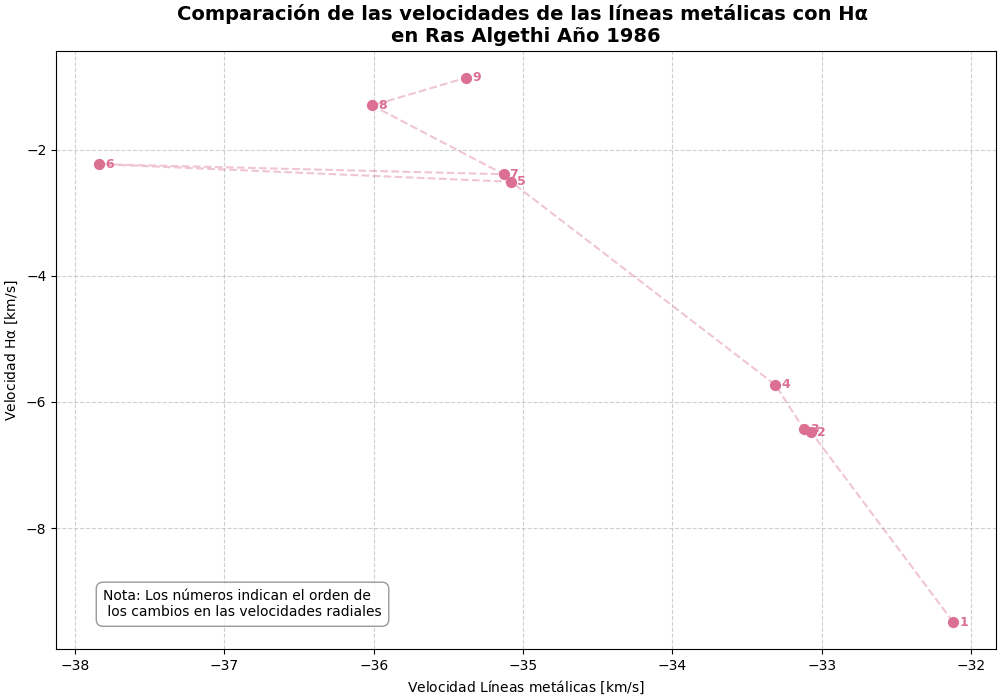

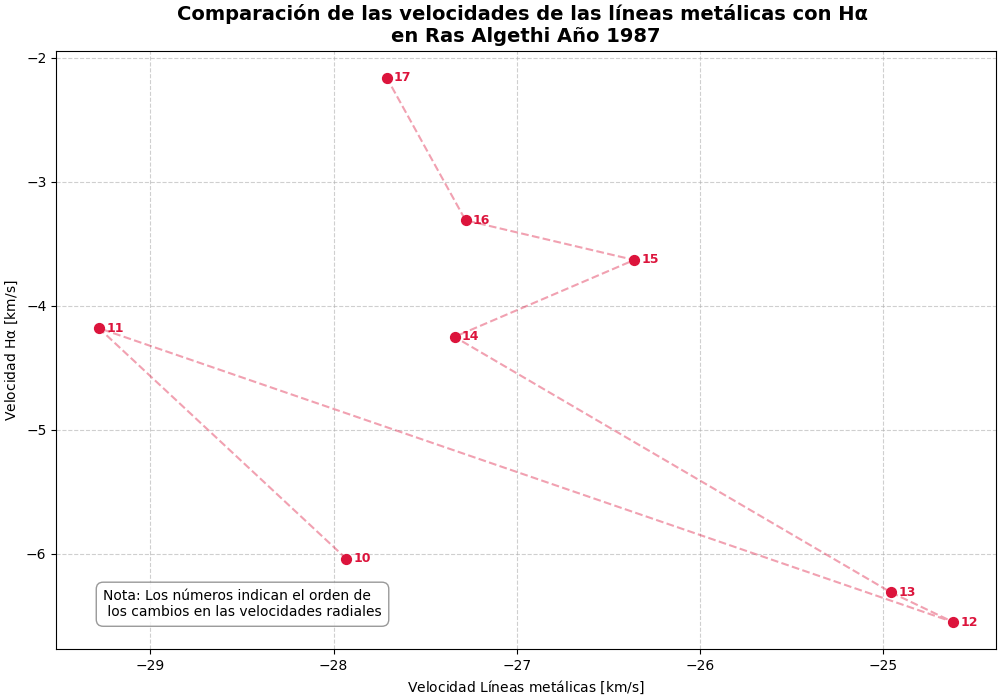

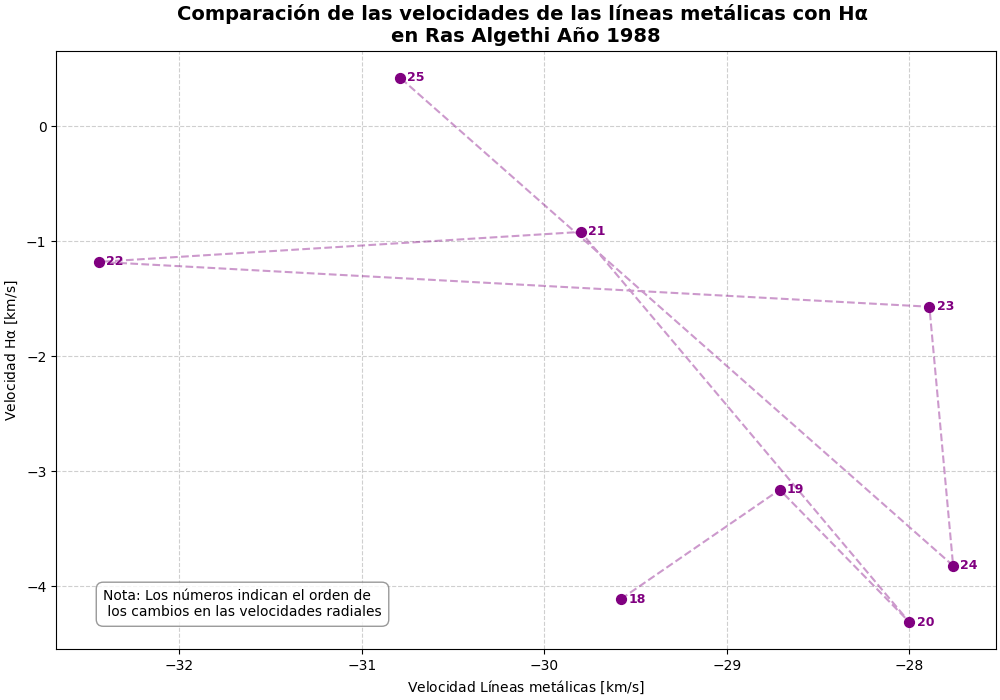

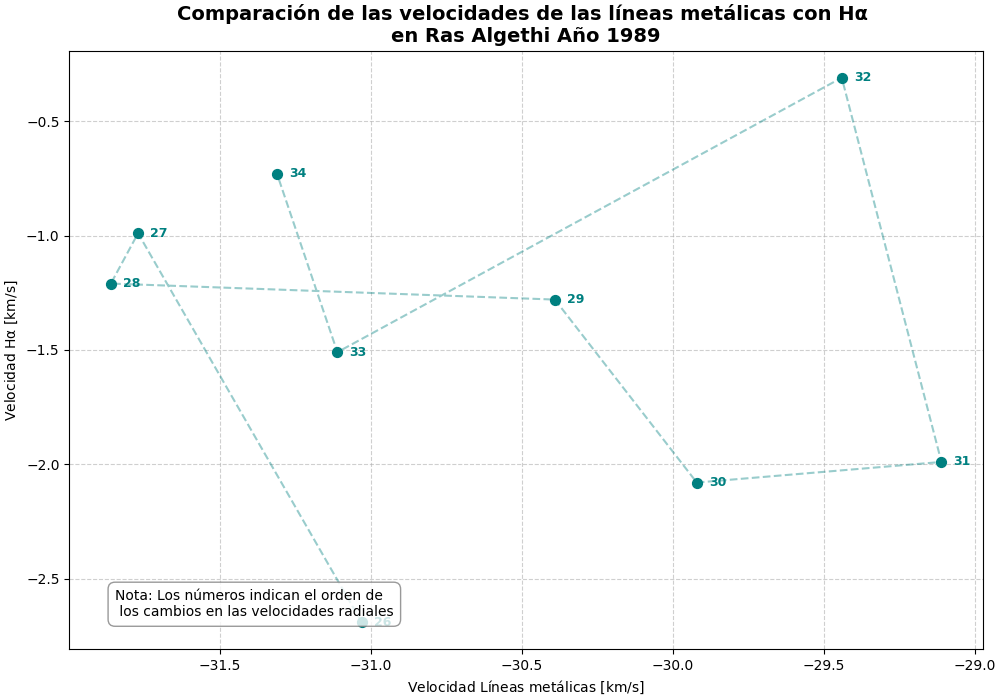

In [42]:
plt.close('all')

# Conversión de días julianos a años
dias_julianos_r_reales = 2440000 + dias_julianos_rasalgethi
observaciones_r = Time(dias_julianos_r_reales, format='jd')
anios_r = [t.year for t in observaciones_r.to_datetime()]

# DataFrame de Ras Algethi
df_rasalgethi = pd.DataFrame({
    'indice_original': range(1, len(dias_julianos_rasalgethi) + 1), 
    'dia_juliano_original': dias_julianos_rasalgethi,
    'v_metal': velocidad_metales_rasalgethi,
    'v_hidrogeno': velocidad_hidrogeno_rasalgethi,
    'anio': anios_r
})

# Colores para cada año
colores_r = ['palevioletred', 'crimson', 'purple', 'teal']
anios_unicos_r = sorted(df_rasalgethi['anio'].unique())

# Creación de gráficas por año
for i, anio_actual in enumerate(anios_unicos_r):
    df_anio = df_rasalgethi[df_rasalgethi['anio'] == anio_actual]
    
    plt.figure(figsize=(10, 7), constrained_layout=True)  
    
    color_actual = colores_r[i % len(colores_r)]
    
    plt.scatter(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, s=50, zorder=3)
    plt.plot(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, linestyle='--', alpha=0.4, zorder=2)

    for _, row in df_anio.iterrows():
        plt.text(
            row['v_metal'] + 0.04,  
            row['v_hidrogeno'],     
            str(int(row['indice_original'])),  
            fontsize=9,
            fontweight='bold',
            va='center',
            color=color_actual
        )

    plt.xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    plt.ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    plt.title(f"Comparación de las velocidades de las líneas metálicas con Hα \nen Ras Algethi Año {anio_actual}", fontsize=14, fontweight='bold')

    ax = plt.gca()

    texto_nota = (
        "Nota: Los números indican el orden de \n los cambios en las velocidades radiales"
    )
    ax.text(
        0.05, 0.05, texto_nota,
        transform=ax.transAxes,
        fontsize=10,
        horizontalalignment='left',
        verticalalignment='bottom',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
    )

    plt.savefig(f"Gráficas estrellas Smith/Ras Algethi/Ras_Algethi_Año_{anio_actual}.png", dpi=300)

    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.subplots_adjust(top=0.85)
    plt.show()

<h5 style="color: #e19edc;"> Gráfica Conjunta</h5>

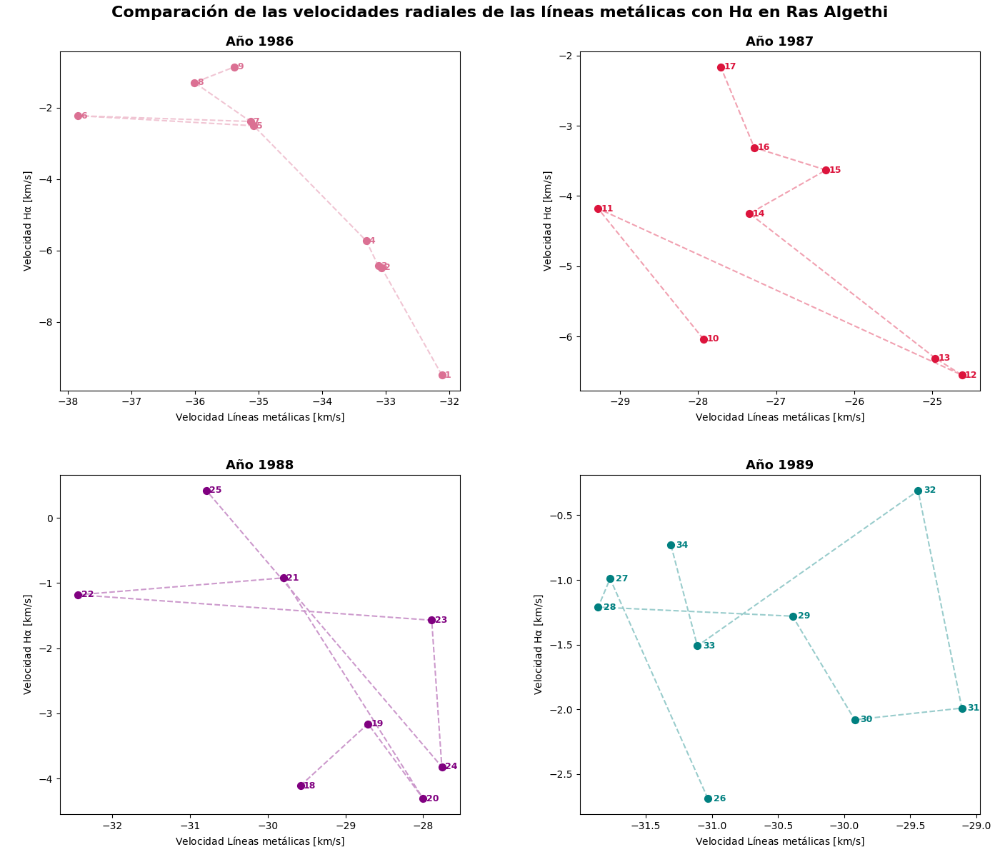

In [51]:
plt.close('all')

carpeta_salida_r = "Gráficas estrellas Smith/Ras Algethi"
os.makedirs(carpeta_salida_r, exist_ok=True)

def dibujar_anio_en_ax(ax, df_anio, anio_actual, color_actual):

    ax.scatter(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, s=50, zorder=3)
    ax.plot(df_anio['v_metal'], df_anio['v_hidrogeno'], color=color_actual, linestyle='--', alpha=0.4, zorder=2)

    for _, row in df_anio.iterrows():
        ax.text(
            row['v_metal'] + 0.04,
            row['v_hidrogeno'],
            str(int(row['indice_original'])),
            fontsize=9,
            fontweight='bold',
            va='center',
            color=color_actual
        )

    ax.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    ax.set_ylabel(r"Velocidad Hα [$\mathrm{km/s}$]")
    ax.set_title(f"Año {anio_actual}", fontsize=13, fontweight='bold')

# Figuras a doble columna

n_anios = len(anios_unicos_r)
n_columnas = 2
n_filas = int(np.ceil(n_anios / n_columnas))

fig = plt.figure(figsize=(14, 6 * n_filas))
gs = GridSpec(n_filas, n_columnas, figure=fig, hspace=0.25, wspace=0.3)

for i, anio_actual in enumerate(anios_unicos_r):

    df_anio = df_rasalgethi[df_rasalgethi['anio'] == anio_actual]
    color_actual = colores_r[i % len(colores_r)]

    fila = i // n_columnas
    columna = i % n_columnas

    es_ultima = (i == n_anios - 1)
    es_impar = (n_anios % 2 == 1)

    if es_ultima and es_impar:

        gs_centro = gs[fila, :].subgridspec(1, 4, wspace=0.15)
        ax = fig.add_subplot(gs_centro[0, 1:3])
    else:
        ax = fig.add_subplot(gs[fila, columna])

    dibujar_anio_en_ax(ax, df_anio, anio_actual, color_actual)

fig.suptitle(r"Comparación de las velocidades radiales de las líneas metálicas con Hα en Ras Algethi",
             fontsize=16, fontweight='bold', y=0.995)
 
fig.subplots_adjust(top=0.94, bottom=0.05, left=0.06, right=0.98)

fig.savefig(f"{carpeta_salida_r}/Rasalgethi_todos_los_años.png", dpi=300, bbox_inches="tight")

plt.show()

<h3 style="color: #e19edc;"> Animaciones de las comparaciones de las velocidades radiales de Ras Algethi</h3>

<h4 style="color: #e19edc;"> Animaciones por año</h4>

In [46]:
for i, anio_actual in enumerate(anios_unicos_r):
    df_anio = df_rasalgethi[df_rasalgethi['anio'] == anio_actual].reset_index(drop=True)
    color_actual = colores_r[i % len(colores_r)]

    fig, ax = plt.subplots(figsize=(8, 6))
    
    margen_x = (df_anio['v_metal'].max() - df_anio['v_metal'].min()) * 0.2 + 0.1
    margen_y = (df_anio['v_hidrogeno'].max() - df_anio['v_hidrogeno'].min()) * 0.2 + 0.1
    ax.set_xlim(df_anio['v_metal'].min() - margen_x, df_anio['v_metal'].max() + margen_x)
    ax.set_ylim(df_anio['v_hidrogeno'].min() - margen_y, df_anio['v_hidrogeno'].max() + margen_y)
    
    ax.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
    ax.set_ylabel(r"Velocidad $H_\alpha$ [$\mathrm{km/s}$]")
    ax.set_title(f"Evolución temporal de Ras Algethi - Año {anio_actual}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Elementos de la animación: punto y trayectoria
    linea_trayectoria, = ax.plot([], [], color=color_actual, linestyle='--', alpha=0.5, zorder=2)
    punto_actual, = ax.plot([], [], marker='o', color=color_actual, markersize=8, zorder=3)
    
    def actualizar_anio(frame):
        x_datos = df_anio['v_metal'].iloc[:frame+1]
        y_datos = df_anio['v_hidrogeno'].iloc[:frame+1]
        
        linea_trayectoria.set_data(x_datos, y_datos)
        if len(x_datos) > 0:
            punto_actual.set_data([x_datos.iloc[-1]], [y_datos.iloc[-1]])
            
        return linea_trayectoria, punto_actual

    # Creamos la animación 
    anim_r = FuncAnimation(fig, actualizar_anio, frames=len(df_anio), interval=300, blit=True)

    anim_r.save(f"Animaciones estrellas Smith/Ras Algethi/rasalgethi_en_{anio_actual}.mp4", writer="ffmpeg", fps=2,  dpi=150)

    plt.close(fig) 
    
    # Animación en Jupyter
    display(HTML(anim_r.to_jshtml()))

<h4 style="color: #e19edc;"> Animación conjunta de Ras Algethi en el periodo de 1986 a 1989</h4>

In [48]:
fig_conjunta_r, ax_c = plt.subplots(figsize=(9, 7))

ax_c.set_xlim(df_rasalgethi['v_metal'].min() - 1, df_rasalgethi['v_metal'].max() + 1)
ax_c.set_ylim(df_rasalgethi['v_hidrogeno'].min() - 1, df_rasalgethi['v_hidrogeno'].max() + 1)
ax_c.set_xlabel(r"Velocidad Líneas metálicas [$\mathrm{km/s}$]")
ax_c.set_ylabel(r"Velocidad $H_\alpha$ [$\mathrm{km/s}$]")
ax_c.set_title(r"Trayectorias conjuntas de Ras Algethi por Año", fontsize=13, fontweight='bold')
ax_c.grid(True, linestyle='--', alpha=0.6)

lineas_conjuntas_r = []
for i, anio_actual in enumerate(anios_unicos_r):
    color_actual = colores_r[i % len(colores_r)]
    l, = ax_c.plot([], [], color=color_actual, linestyle='--', alpha=0.6, label=f"Año {anio_actual}", zorder=2)
    lineas_conjuntas_r.append(l)

punto_unico, = ax_c.plot([], [], marker='o', color='black', markeredgecolor='white', markersize=9, zorder=4, label="Posición actual")

ax_c.legend(loc='upper right', framealpha=0.9)

# Se almacenan los datos por año
datos_por_anio_r = []
for anio_actual in anios_unicos_r:
    df_anio = df_rasalgethi[df_rasalgethi['anio'] == anio_actual].reset_index(drop=True)
    datos_por_anio_r.append(df_anio)

secuencia_frames_r = []
for i, df_anio in enumerate(datos_por_anio_r):
    for punto_idx in range(len(df_anio)):
        secuencia_frames_r.append((i, punto_idx))

def actualizar_conjunto(frame):
    anio_idx_actual, punto_idx_actual = secuencia_frames_r[frame]

    # Años pasados (Se grafican las trayectorias completas de los años anteriores)
    for i in range(anio_idx_actual):
        df_anio = datos_por_anio_r[i]
        x_vals = list(df_anio['v_metal'])
        y_vals = list(df_anio['v_hidrogeno'])

        # Unión entre años distintos
        if i > 0 and len(datos_por_anio_r[i - 1]) > 0:
            x_vals = [datos_por_anio_r[i - 1]['v_metal'].iloc[-1]] + x_vals
            y_vals = [datos_por_anio_r[i - 1]['v_hidrogeno'].iloc[-1]] + y_vals
        lineas_conjuntas_r[i].set_data(x_vals, y_vals)

    # Años futuros
    for i in range(anio_idx_actual + 1, len(datos_por_anio_r)):
        lineas_conjuntas_r[i].set_data([], [])

    # Año actual
    df_actual = datos_por_anio_r[anio_idx_actual]
    x_datos = list(df_actual['v_metal'].iloc[:punto_idx_actual + 1])
    y_datos = list(df_actual['v_hidrogeno'].iloc[:punto_idx_actual + 1])

    # Unión entre años distintos
    if anio_idx_actual > 0 and len(datos_por_anio_r[anio_idx_actual - 1]) > 0:
        x_datos = [datos_por_anio_r[anio_idx_actual - 1]['v_metal'].iloc[-1]] + x_datos
        y_datos = [datos_por_anio_r[anio_idx_actual - 1]['v_hidrogeno'].iloc[-1]] + y_datos

    lineas_conjuntas_r[anio_idx_actual].set_data(x_datos, y_datos)

    # Punto estudio
    punto_unico.set_data([x_datos[-1]], [y_datos[-1]])

    return lineas_conjuntas_r + [punto_unico]

anim_conjunta_r = FuncAnimation(
    fig_conjunta_r, actualizar_conjunto,
    frames=len(secuencia_frames_r), interval=250, blit=True
)

anim_conjunta_r.save("Animaciones estrellas Smith/Ras Algethi/rasalgethi_trayectorias.mp4", writer="ffmpeg", fps=2,  dpi=150)

plt.close(fig_conjunta_r)

display(HTML(anim_conjunta_r.to_jshtml()))

<h3 style="color: #e19edc;"> Gráficas de velocidad radial en función del tiempo</h3>

In [26]:
# Datos como arrays para operaciones

# Betelgeuse
t_b   = np.asarray(dias_julianos_betelgeuse, dtype=float)
v_m_b = np.asarray(velocidad_metales_betelgeuse, dtype=float)
v_h_b = np.asarray(velocidad_hidrogeno_betelgeuse, dtype=float)

# Antares

t_a   = np.asarray(dias_julianos_antares, dtype=float)
v_m_a = np.asarray(velocidad_metales_antares, dtype=float)
v_h_a = np.asarray(velocidad_hidrogeno_antares, dtype=float)

# Ras Algethi
t_r   = np.asarray(dias_julianos_rasalgethi, dtype=float)
v_m_r = np.asarray(velocidad_metales_rasalgethi, dtype=float)
v_h_r = np.asarray(velocidad_hidrogeno_rasalgethi, dtype=float)


# Estilo gráficos
estilos = {
    'metales':   dict(color='darkorchid',   marker='^', label='Líneas metálicas'),
    'hidrogeno': dict(color='cornflowerblue', marker='s', label='Hα'),
    }

In [27]:
# Tendencia sinosoidal: A * sin(2πt/P + fase) + C
def sinusoide(t, A, P, fase, C):
    return A * np.sin(2*np.pi*t/P + fase) + C

def ajustar(t, v, P_inicial):
    p0 = [np.std(v)*np.sqrt(2), P_inicial, 0, np.mean(v)]
    popt, pcov = curve_fit(sinusoide, t, v, p0=p0, maxfev=20000)
    return popt

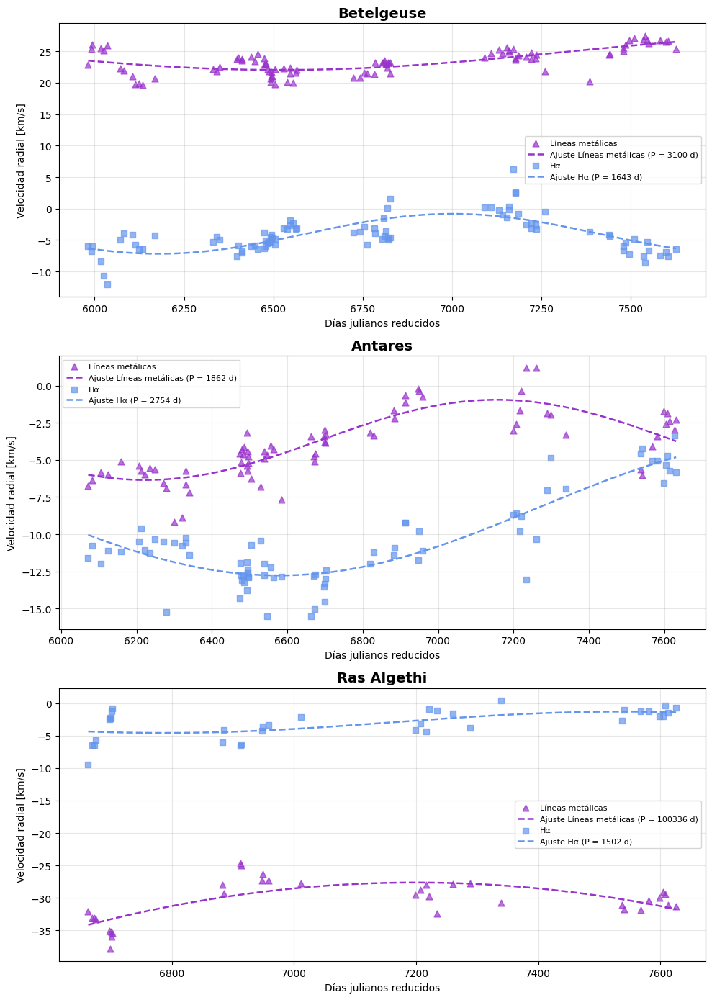

In [35]:
# Una estrella por eje
def graficar_estrella(ax, t, v_m, v_h, nombre, P0):
    t_fino = np.linspace(t.min(), t.max(), 1000)

    for clave, v in [('metales', v_m), ('hidrogeno', v_h)]:
        est = estilos[clave]
        ax.scatter(t, v, color=est['color'], marker=est['marker'],
                   s=40, alpha=0.7, label=est['label'])

        popt = ajustar(t, v, P0)
        ax.plot(t_fino, sinusoide(t_fino, *popt), color=est['color'], linestyle='--', linewidth=1.8, label=f"Ajuste {est['label']} (P = {abs(popt[1]):.0f} d)")

    ax.set_xlabel('Días julianos reducidos')
    ax.set_ylabel('Velocidad radial [km/s]')
    ax.set_title(nombre, fontsize=14, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

# Gráfica con las tres estrellas conjuntas
fig, axs = plt.subplots(3, 1, figsize=(10, 14))

graficar_estrella(axs[0], t_b, v_m_b, v_h_b, 'Betelgeuse',  P0=2100)  # días
graficar_estrella(axs[1], t_a, v_m_a, v_h_a, 'Antares',     P0=2191)  # días
graficar_estrella(axs[2], t_r, v_m_r, v_h_r, 'Ras Algethi', P0=1350)  # días

plt.tight_layout()
plt.show()

In [37]:
# estrellas = [
#     (t_b, v_m_b, v_h_b, 'Betelgeuse',  2100),
#     (t_a, v_m_a, v_h_a, 'Antares',     2191),
#     (t_r, v_m_r, v_h_r, 'Ras Algethi', 1350),
# ]

# for t, v_m, v_h, nombre, P0 in estrellas:
#     fig, ax = plt.subplots(figsize=(10, 6))
#     graficar_estrella(ax, t, v_m, v_h, nombre, P0)
#     plt.tight_layout()

#     nombre_archivo = nombre.lower().replace(' ', '_')
#     fig.savefig(f'velocidad_{nombre_archivo}.png', dpi=300, bbox_inches='tight')
#     plt.show()